In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("/content/crop_production.csv")
print(df.shape)
df.head()

(246091, 7)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


In [2]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246091 entries, 0 to 246090
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   State_Name     246091 non-null  object 
 1   District_Name  246091 non-null  object 
 2   Crop_Year      246091 non-null  int64  
 3   Season         246091 non-null  object 
 4   Crop           246091 non-null  object 
 5   Area           246091 non-null  float64
 6   Production     242361 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 13.1+ MB


,Crop_Year,Area,Production
count,246091.000000,2.460910e+05,2.423610e+05
mean,2005.643018,1.200282e+04,5.825034e+05
std,4.952164,5.052340e+04,1.706581e+07
min,1997.000000,4.000000e-02,0.000000e+00
25%,2002.000000,8.000000e+01,8.800000e+01
50%,2006.000000,5.820000e+02,7.290000e+02
75%,2010.000000,4.392000e+03,7.023000e+03
max,2015.000000,8.580100e+06,1.250800e+09


In [5]:
STATE, CROP, SEASON, YEAR = "State_Name", "Crop", "Season", "Crop_Year"
AREA, PROD = "Area", "Production"
if "Yield" not in df.columns:
    df["Yield"] = df[PROD] / df[AREA]
print(df.columns.tolist())

['State_Name', 'District_Name', 'Crop_Year', 'Season', 'Crop', 'Area', 'Production', 'Yield']


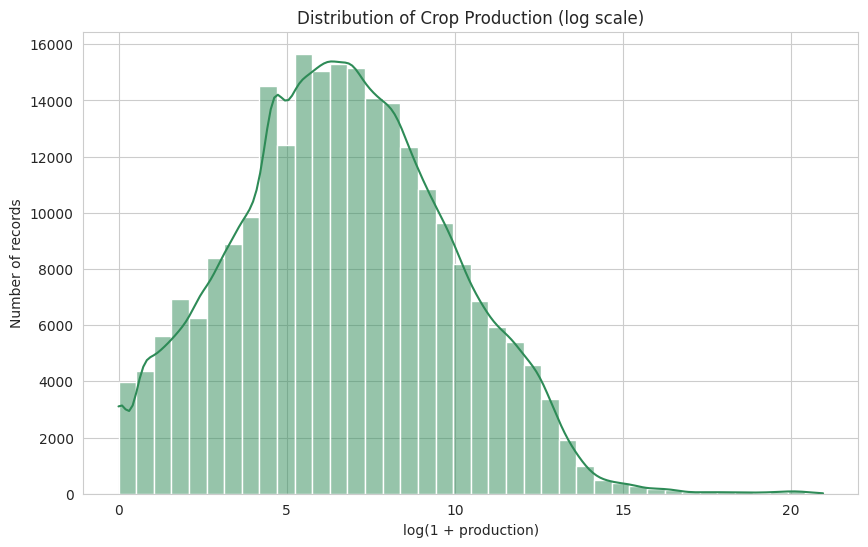

In [6]:
plt.figure()
sns.histplot(np.log1p(df[PROD]), bins=40, kde=True, color="seagreen")
plt.title("Distribution of Crop Production (log scale)")
plt.xlabel("log(1 + production)")
plt.ylabel("Number of records")
plt.savefig("fig1_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

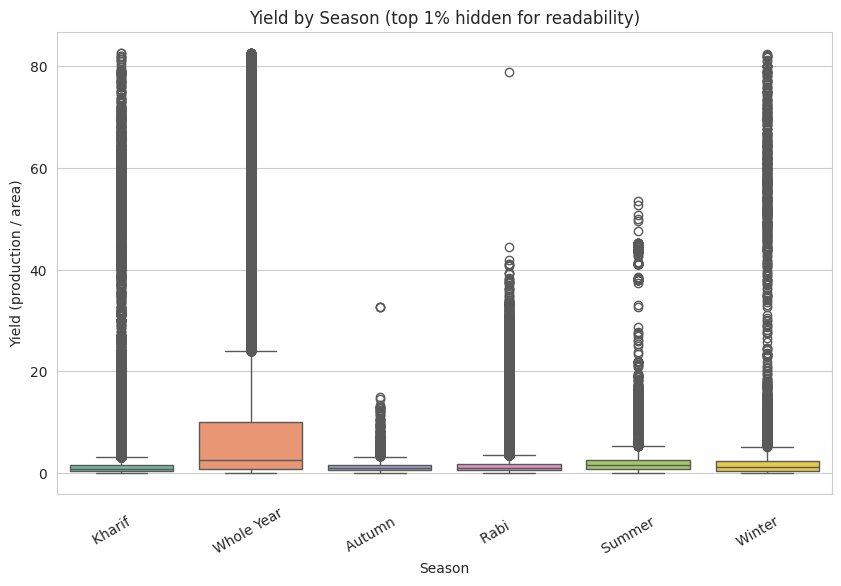

In [13]:
cap = df["Yield"].quantile(0.99)
plot_df = df[df["Yield"] <= cap]
plt.figure()
sns.boxplot(data=plot_df, x=SEASON, y="Yield", hue=SEASON, palette="Set2", legend=False)
plt.title("Yield by Season (top 1% hidden for readability)")
plt.xlabel("Season")
plt.ylabel("Yield (production / area)")
plt.xticks(rotation=30)
plt.savefig("fig2_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

/tmp/ipykernel_1530/932383468.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_states.values, y=top_states.index, palette="viridis")


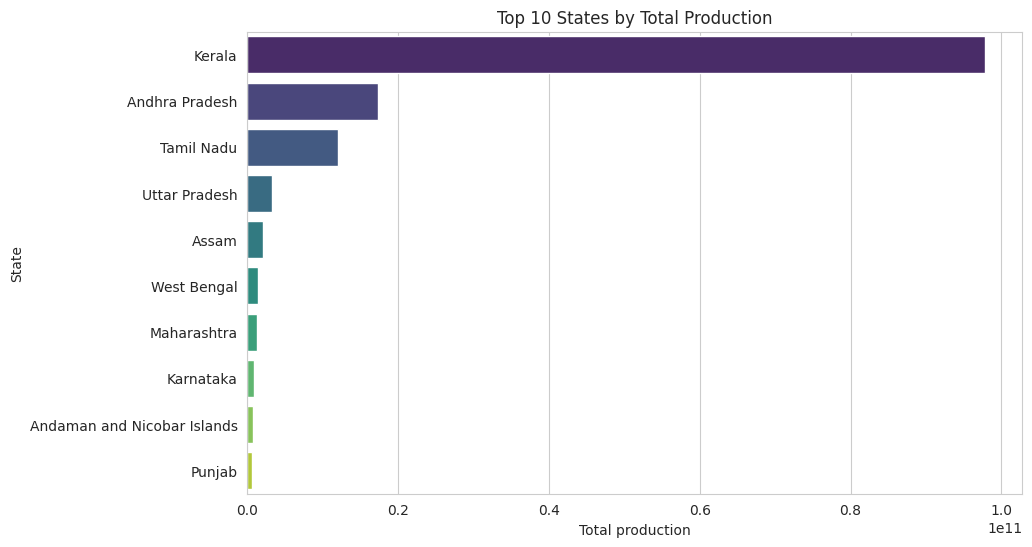

State_Name
Kerala                         9.788005e+10
Andhra Pradesh                 1.732459e+10
Tamil Nadu                     1.207644e+10
Uttar Pradesh                  3.234493e+09
Assam                          2.111752e+09
West Bengal                    1.397904e+09
Maharashtra                    1.263641e+09
Karnataka                      8.634298e+08
Andaman and Nicobar Islands    7.182232e+08
Punjab                         5.863850e+08
Name: Production, dtype: float64


In [9]:
top_states = df.groupby(STATE)[PROD].sum().sort_values(ascending=False).head(10)
plt.figure()
sns.barplot(x=top_states.values, y=top_states.index, palette="viridis")
plt.title("Top 10 States by Total Production")
plt.xlabel("Total production")
plt.ylabel("State")
plt.savefig("fig3_bar_states.png", dpi=150, bbox_inches="tight")
plt.show()
print(top_states)

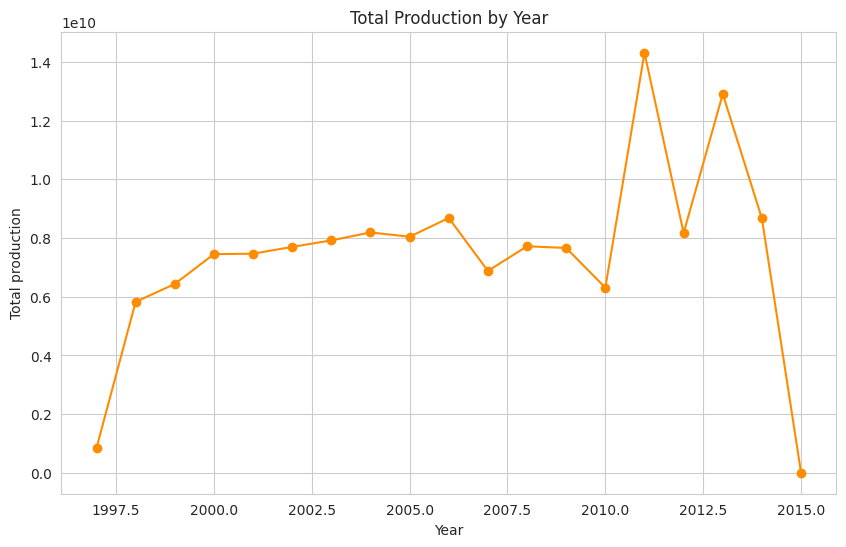

Crop_Year
1997     8899
1998    11533
1999    12515
2000    13658
2001    13361
2002    16671
2003    17287
2004    14117
2005    13799
2006    14328
2007    14526
2008    14550
2009    14116
2010    14065
2011    14071
2012    13410
2013    13650
2014    10973
2015      562
dtype: int64


In [10]:
yearly = df.groupby(YEAR)[PROD].sum()
plt.figure()
plt.plot(yearly.index, yearly.values, marker="o", color="darkorange")
plt.title("Total Production by Year")
plt.xlabel("Year")
plt.ylabel("Total production")
plt.grid(True)
plt.savefig("fig4_line_trend.png", dpi=150, bbox_inches="tight")
plt.show()
print(df.groupby(YEAR).size())

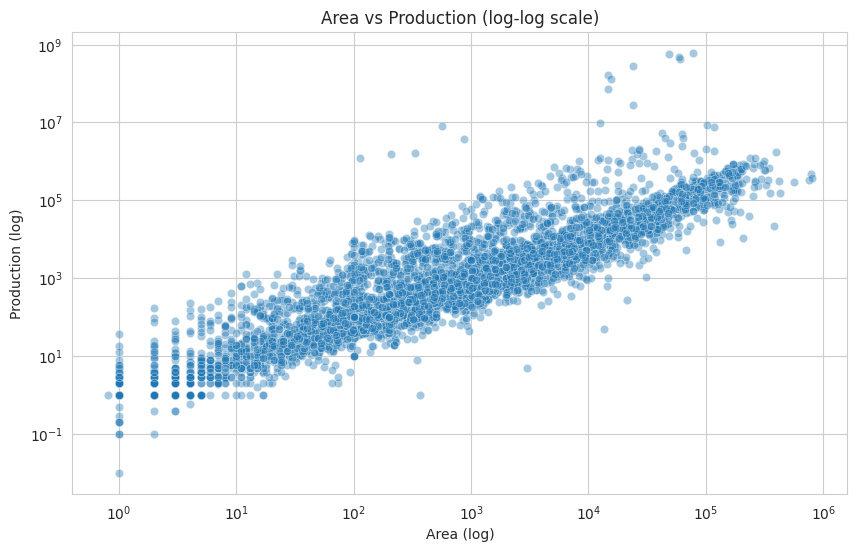

In [11]:
sample = df.sample(min(5000, len(df)), random_state=1)
plt.figure()
sns.scatterplot(data=sample, x=AREA, y=PROD, alpha=0.4)
plt.xscale("log"); plt.yscale("log")
plt.title("Area vs Production (log-log scale)")
plt.xlabel("Area (log)")
plt.ylabel("Production (log)")
plt.savefig("fig5_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

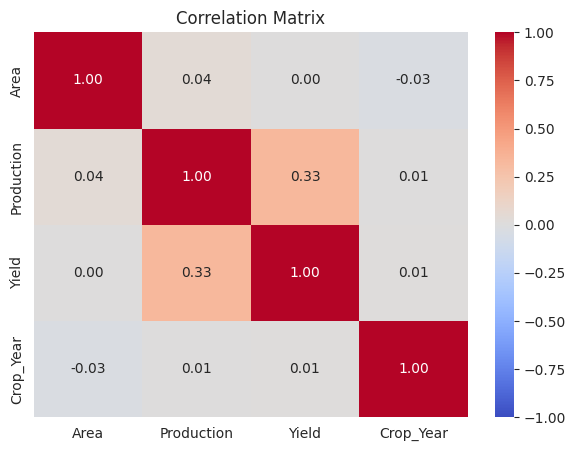

In [14]:
num = df[[AREA, PROD, "Yield"]].copy()
if YEAR in df.columns:
    num[YEAR] = df[YEAR]
plt.figure(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.savefig("fig6_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

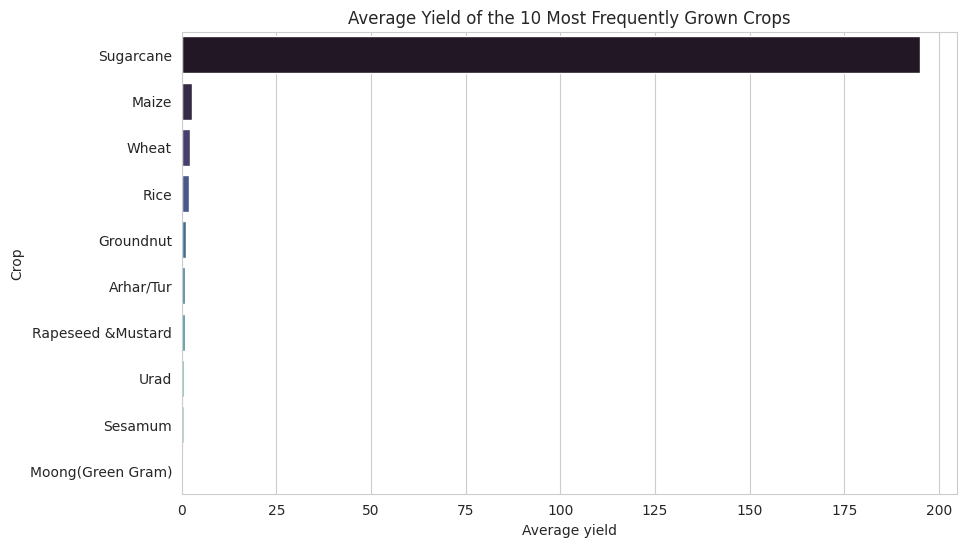

In [16]:
top_crops = df[CROP].value_counts().head(10).index
avg_yield = df[df[CROP].isin(top_crops)].groupby(CROP)["Yield"].mean().sort_values(ascending=False)
plt.figure()
sns.barplot(x=avg_yield.values, y=avg_yield.index, hue=avg_yield.index, palette="mako", legend=False)
plt.title("Average Yield of the 10 Most Frequently Grown Crops")
plt.xlabel("Average yield")
plt.ylabel("Crop")
plt.savefig("fig7_bar_crops.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
print("Season with highest total production:\n", df.groupby(SEASON)[PROD].sum().sort_values(ascending=False).head(3))
print("\nCorrelation area vs production:", round(df[AREA].corr(df[PROD]), 2))
print("\nTop 5 crops by total production:\n", df.groupby(CROP)[PROD].sum().sort_values(ascending=False).head(5))
print("\nYear with highest production:", yearly.idxmax(), "| lowest:", yearly.idxmin())

Season with highest total production:
 Season
Whole Year     1.344248e+11
Kharif         4.029970e+09
Rabi           2.051688e+09
Name: Production, dtype: float64

Correlation area vs production: 0.04

Top 5 crops by total production:
 Crop
Coconut      1.299816e+11
Sugarcane    5.535682e+09
Rice         1.605470e+09
Wheat        1.332826e+09
Potato       4.248263e+08
Name: Production, dtype: float64

Year with highest production: 2011 | lowest: 2015
